In [3]:
# =============================================================================
# CELL 1 -- Configuration, imports and style
#
# Companion to 01.5.1_TNG50_individual.ipynb: instead of searching for one
# clean Sub-DLA sightline, this notebook re-runs the exact SAME three-mode
# fake_spectra extraction (None / HCD_only / Forest_only, peaks+blend,
# tophat kernel) and the exact same FIG 2d (3-panel: real space, velocity,
# flux) for three SPECIFIC, already-identified skewers: cases (b), (d) and
# (e) of 14_Temperatures.ipynb's CELL C ("the six example spectra").
#
# Those three cases are outliers/failure-mode examples picked by CELL A/B of
# 14_Temperatures.ipynb from the production HCD_only pickle (which only ever
# ran filter_mode="HCD_only" -- see run_analysis_batched in
# 10_variance.ipynb). That pickle has no Forest_only/None channels
# and no per-cell watershed system decomposition, so FIG 2d cannot be built
# from it directly -- the sightline has to be re-extracted here, through the
# same 3-mode pipeline 01.5.1_ uses.
#
#   CELL 2  capture_cells / merge_captures / suppress_c_stdout (unchanged
#           from 01.5.1_'s CELL 1)
#   CELL 3  sightline geometry: wrap() and sightline_for() (unchanged from
#           01.5.1_'s CELL 2, minus the impact-parameter SEARCH grid, which
#           this notebook has no use for -- every case's exact r_multiplier
#           is already known)
#   CELL 4  the three CASES (b), (d), (e) -- halo_id/axis/r_multiplier/
#           position_tag identified by reproducing 14_Temperatures.ipynb's
#           CELL A + CELL B against its cached Voigt-fit table
#   CELL 5  run_one_sightline (unchanged from 01.5.1_'s CELL 3)
#   CELL 6  make_fig2d_for_case() -- alignment (01.5.1_'s CELL 5) +
#           position-space prep (CELL 7) + FIG 2d itself (CELL 8), all
#           three folded into one function so they run once per case
#           instead of once per notebook
#   CELL 7  run it for (b), (d) and (e)
# =============================================================================
%matplotlib widget

import os
import sys
from contextlib import contextmanager

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

REPO_DIR = os.path.abspath("..")          # notebooks_TNG/ -> FakeSpectra_DLAs/
sys.path.insert(0, os.path.join(REPO_DIR, "tools"))

import utils
import radii_skewers
from fake_spectra import spectra

if not hasattr(spectra, "HCD_ALGORITHMS"):
    raise ImportError(f"{spectra.__file__} is not the HCD fork "
                      "(no HCD_ALGORITHMS)")
print("using:", spectra.__file__)
print("algorithms:", spectra.HCD_ALGORITHMS)

# --- simulation --------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"   # no "/output": groups_025/ lives here
SNAP_NUM  = 25                            # z ~ 3.01
SIM_TYPE  = "TNG"
RES_KMS   = 10.0                          # production sampling, same as 01.5.1_

HCD_ALGORITHM = "peaks+blend"
# All three filter modes must share a kernel: the Voronoi kernel rebuilds its
# segments from whatever particles it is given, so a filtered subset would
# silently redistribute the removed volume onto the survivors.
KERNEL = "tophat"

# --- what to plot --------------------------------------------------------------
HCD_LOG_NHI   = 17.2
XLIM_FIG2     = None       # e.g. (-2000, 2000) km/s
FINE_ALIGN    = True       # re-centre on the absorber, per Sec. 2.4
MAP_SLAB_R200 = 5.0        # +/-N R200 association window, for panel 1's
                           # shading -- matches halo_radius_cut below

PLOT_DIR = os.path.join(REPO_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)
DEFINITIVES_DIR = os.path.join(REPO_DIR, "definitives")
os.makedirs(DEFINITIVES_DIR, exist_ok=True)

# --- style (identical to 01.5_/01.5.1_) ---------------------------------------
plt.rc('font', family='serif', size=16)
plt.rcParams.update({
    "mathtext.fontset": "cm", "text.usetex": False,
    "axes.linewidth": 1.6, "axes.grid": False,
    "axes.labelsize": 19, "legend.fontsize": 15,
    "xtick.labelsize": 16, "ytick.labelsize": 16,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.major.size": 8, "ytick.major.size": 8,
    "xtick.minor.size": 4, "ytick.minor.size": 4,
    "xtick.major.width": 1.4, "ytick.major.width": 1.4,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "legend.frameon": True, "legend.framealpha": 0.92,
    "figure.dpi": 72, "savefig.dpi": 300, "savefig.bbox": "tight",
})

# Okabe-Ito, verbatim from the manuscript preamble.
colors = [
    "#E69F00", "#56B4E9", "#009E73", "#F0E442", "#0072B2",
    "#D55E00", "#CC79A7", "#000000", "#999999", "#553388",
]
OI = {"orange": colors[0], "sky": colors[1], "green": colors[2],
      "yellow": colors[3], "blue": colors[4], "vermillion": colors[5],
      "purple": colors[6], "black": colors[7], "grey": colors[8],
      "violet": colors[9]}
plt.rcParams["axes.prop_cycle"] = mpl.cycler(color=colors)

# Absorber-class colours -- SAME mapping used throughout the project (see
# 10_variance.ipynb's ridgeline/mass-bin figures and
# 14_Temperatures.ipynb's CLASS_COLORS): forest E69F00, LLS 56B4E9, Sub-DLA
# 009E73, Small-DLA F0E442, Large-DLA 0072B2.
CLASS_COLORS = {
    "Forest":    "#E69F00",
    "LLS":       "#56B4E9",
    "Sub_DLA":   "#009E73",
    "Small_DLA": "#F0E442",
    "Large_DLA": "#0072B2",
}


using: /home/vroberto/fake_spectra_fork/fake_spectra/spectra.py
algorithms: ('peaks', 'peaks+blend', 'region_growing')


In [4]:
# =============================================================================
# CELL 2 -- capture_cells / merge_captures / suppress_c_stdout
#
# Unchanged from 01.5_/01.5.1_'s CELL 1.
#
# The fork discards its internal mask, so we read it off the three filter modes:
#   "None"        -> every cell near the sightline
#   "HCD_only"    -> the cells the filter flagged
#   "Forest_only" -> the complement
#
# THREE TRAPS:
#  1. Shapes. Each mode runs three passes (tau, column density, temperature);
#     only the tau pass carries full velocities and temperatures. Keep get_tau
#     only, or concatenating mixes (N,3) with (1,).
#  2. Units. elem_den is in code units, and in the get_temp pass it is not even
#     n_HI. Physical n_HI = (elem_den / rscale) * amumass.
#  3. Re-entrancy. Under peaks+blend the fork's _blend_test calls the
#     interpolator once per CANDIDATE basin while still deciding the mask.
#     Those are hypotheses, not the answer; drop anything captured inside it.
# =============================================================================
@contextmanager
def suppress_c_stdout():
    """Silence the C interpolator's progress printing (it writes to fd 1)."""
    sys.stdout.flush()
    saved = os.dup(1)
    devnull = os.open(os.devnull, os.O_WRONLY)
    try:
        os.dup2(devnull, 1)
        yield
    finally:
        os.dup2(saved, 1)
        os.close(devnull)
        os.close(saved)


@contextmanager
def capture_cells(store):
    original_interp = spectra.Spectra._do_interpolation_work
    original_blend = getattr(spectra.Spectra, "_blend_test", None)
    state = {"in_blend": False, "n_blend": 0}

    def interp_wrapper(self, pos, vel, elem_den, temp, hh, amumass, line,
                       get_tau, custom_axis=None, custom_cofm=None):
        if state["in_blend"]:
            state["n_blend"] += 1
        else:
            store.append(dict(
                get_tau=bool(get_tau), amumass=float(amumass),
                rscale=float(self.rscale),
                pos=np.array(pos, copy=True), vel=np.array(vel, copy=True),
                den=np.array(elem_den, copy=True),
                temp=np.array(temp, copy=True)))
        return original_interp(self, pos, vel, elem_den, temp, hh, amumass,
                               line, get_tau, custom_axis=custom_axis,
                               custom_cofm=custom_cofm)

    def blend_wrapper(self, *a, **kw):
        prev = state["in_blend"]
        state["in_blend"] = True
        try:
            return original_blend(self, *a, **kw)
        finally:
            state["in_blend"] = prev

    spectra.Spectra._do_interpolation_work = interp_wrapper
    if original_blend is not None:
        spectra.Spectra._blend_test = blend_wrapper
    try:
        yield store
    finally:
        spectra.Spectra._do_interpolation_work = original_interp
        if original_blend is not None:
            spectra.Spectra._blend_test = original_blend
        if state["n_blend"]:
            print(f"    (dropped {state['n_blend']} blend-test interpolations)")


EMPTY_CELLS = dict(pos=np.empty((0, 3)), vel=np.empty((0, 3)),
                   nHI=np.empty(0), temp=np.empty(0))


def merge_captures(store):
    """Keep the get_tau pass, convert the density to physical n_HI [cm^-3]."""
    chunks = [c for c in store if c["get_tau"]]
    if not chunks:
        return dict(EMPTY_CELLS)
    for c in chunks:
        n = c["pos"].shape[0]
        if c["vel"].shape[0] != n or c["temp"].shape[0] != n:
            raise RuntimeError("ragged get_tau chunk; the fork's interpolation "
                               "signature changed -- update this wrapper")
    out = {k: np.concatenate([c[k] for c in chunks], axis=0)
           for k in ("pos", "vel", "temp")}
    out["nHI"] = np.concatenate(
        [(c["den"] / c["rscale"]) * c["amumass"] for c in chunks], axis=0)
    return out


In [5]:
# =============================================================================
# CELL 3 -- Sightline geometry: wrap() and sightline_for()
#
# Same helpers as 01.5_/01.5.1_'s CELL 2, minus the impact-parameter SEARCH
# grid (build_r_multipliers/snap_impact/R_MULTIPLIERS): every case below
# already carries its own exact r_multiplier, read straight off the
# production pickle, so there is nothing to snap to a grid.
# =============================================================================
def wrap(d, period):
    """Signed separation on a periodic axis, in (-period/2, +period/2]."""
    return (np.asarray(d) + period / 2.0) % period - period / 2.0


ctx = utils.SimulationContext(BASE_PATH, SNAP_NUM, sim_type=SIM_TYPE)
finder = utils.HaloFinder(ctx)

for _p in (os.path.join(BASE_PATH, f"groups_{SNAP_NUM:03d}",
                        f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"),
           os.path.join(BASE_PATH, f"snapdir_{SNAP_NUM:03d}")):
    if not os.path.exists(_p):
        raise FileNotFoundError(f"not found: {_p}\nCheck BASE_PATH={BASE_PATH!r}")


def sightline_for(halo_info, axis_1indexed, b_mult, tag):
    """cofm and axis arrays for one skewer, using the production geometry."""
    g = radii_skewers.SkewerGeometry(ctx, halo_info)
    for sk in g.generate_skewers(r_multiplier=b_mult):
        if sk['axis'] == axis_1indexed - 1 and sk['position_tag'] == tag:
            cofm = np.mod(np.asarray(halo_info['cm'], float) + sk['offset_vec'],
                          halo_info['box_size'])
            return (np.array([cofm], dtype=np.float64),
                    np.array([axis_1indexed], dtype=np.int32), sk)
    raise RuntimeError(f"no skewer with axis={axis_1indexed}, tag={tag}")


In [6]:
# =============================================================================
# CELL 4 -- The three cases: (b), (d), (e) from 14_Temperatures.ipynb's CELL C
#
# Identified by reproducing 14_Temperatures.ipynb's CELL A (classification)
# and CELL B (example-picking) against its cached Voigt-fit table
# (TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42_voigtfit.pkl, the CELL 1
# fit cached to disk), with no changes to that picking logic. 'axis' below is
# the 1-INDEXED convention sightline_for()/fake_spectra expect (fake_spectra's
# axis = the production pickle's 0-indexed 'axis' column + 1); 'r_multiplier'
# and 'position_tag' are copied verbatim from that same row, so
# sightline_for() reconstructs the IDENTICAL skewer the production run used.
#
#   (b) 'large negative Delta, low chi2'  -- an LLS the fit badly UNDER-shoots
#   (d) 'small Delta, VERY high chi2'     -- a sub-DLA fit that recovers
#                                            log N_HI but with a terrible chi2
#   (e) the OVERSHOOT/contaminated case   -- an LLS whose fit OVER-shoots
#                                            because a second, separate
#                                            absorption complex sits nearby
#
# nhi_class/log_n_hi/fit_log_nhi/chi2/dlogN are carried along only for the
# printout below -- CELL 6 recomputes everything that matters (basins,
# systems, channel colours, ...) from the FRESH 3-mode extraction, not from
# these cached numbers.
# =============================================================================
CASES = [
    dict(letter='b', halo_id=591, axis=3, r_multiplier=0.8189555813651156,
        position_tag='Left',
        nhi_class='LLS', log_n_hi=17.736562816522763,
        fit_log_nhi=15.436585350237102, dlogN=-2.299977466285661,
        chi2=1.145197870391393),
    dict(letter='d', halo_id=5, axis=2, r_multiplier=0.0,
        position_tag='Center',
        nhi_class='sub-DLA', log_n_hi=20.013757992813325,
        fit_log_nhi=20.014614720115294, dlogN=0.0008567272219690209,
        chi2=5.007268452907373),
    dict(letter='e', halo_id=280, axis=3, r_multiplier=0.1885848922832098,
        position_tag='Left',
        nhi_class='LLS', log_n_hi=17.27966785952704,
        fit_log_nhi=18.861542741068096, dlogN=1.5818748815410562,
        chi2=13.471291649191986),
]

print(f"{'case':>4} {'halo_id':>8} {'axis':>4} {'tag':>7} {'r_mult':>9} "
      f"{'class':>9} {'log N_sim':>9} {'log N_fit':>9} {'dlogN':>8} {'chi2':>8}")
for c in CASES:
    print(f"({c['letter']:>2}) {c['halo_id']:>8d} {c['axis']:>4d} "
          f"{c['position_tag']:>7s} {c['r_multiplier']:>9.4f} "
          f"{c['nhi_class']:>9s} {c['log_n_hi']:>9.2f} {c['fit_log_nhi']:>9.2f} "
          f"{c['dlogN']:>+8.2f} {c['chi2']:>8.3g}")


case  halo_id axis     tag    r_mult     class log N_sim log N_fit    dlogN     chi2
( b)      591    3    Left    0.8190       LLS     17.74     15.44    -2.30     1.15
( d)        5    2  Center    0.0000   sub-DLA     20.01     20.01    +0.00     5.01
( e)      280    3    Left    0.1886       LLS     17.28     18.86    +1.58     13.5


In [7]:
# =============================================================================
# CELL 5 -- EXTRACTION: run_one_sightline, unchanged from 01.5_/01.5.1_'s CELL 3
#
# The only function that touches the snapshot (three spectra.Spectra() calls
# per case -- filter_mode None / HCD_only / Forest_only, sharing one
# sightline). Called once per case in CELL 6/7 below.
# =============================================================================
MODES = ("None", "HCD_only", "Forest_only")


def run_one_sightline(halo_info, cofm, axis_arr, res_kms=None):
    res_kms = RES_KMS if res_kms is None else res_kms
    out, meta = {}, {}
    for mode in MODES:
        store = []
        with capture_cells(store), suppress_c_stdout():
            ss = spectra.Spectra(
                int(SNAP_NUM), BASE_PATH, cofm=cofm, axis=axis_arr,
                res=res_kms, savefile=f"unused_{halo_info['id']}_{mode}.hdf5",
                reload_file=True, kernel=KERNEL, MPI=None, quiet=True,
                filter_mode=mode, hcd_algorithm=HCD_ALGORITHM,
                units=ctx.units, halo_r200=float(halo_info['r200']),
                halo_radius_cut=utils.HALO_RADIUS_CUT,
                **utils.SPECTRA_GAS_KWARGS)    # same star-forming gas model as the pipeline
            tau = ss.get_tau("H", 1, 1215)[0]
            colden = ss.get_col_density("H", 1)[0]
            temp = ss.get_temp("H", 1)[0]

        out[mode] = dict(flux=np.exp(-tau), tau=tau, colden=colden, temp=temp,
                         cells=merge_captures(store))

        if not meta:      # geometry and cosmology: identical in all modes
            meta = dict(nbins=ss.nbins, vmax=ss.vmax, velfac=ss.velfac,
                        box=ss.box, red=ss.red, rscale=ss.rscale)
        if mode == "HCD_only":
            meta.update(
                selection_thresh=ss.hcd_selection_thresh,
                peak_smooth_kms=ss.hcd_peak_smooth_kms,
                peak_contrast=ss.hcd_peak_contrast,
                blend_flux_thresh=ss.hcd_blend_flux_thresh,
                basin_info=dict(getattr(ss, "hcd_basin_info", {})))

        tot = colden.sum()
        print(f"  {mode:12s} -> {out[mode]['cells']['pos'].shape[0]:6d} cells, "
              f"log10 N_HI = {np.log10(tot) if tot > 0 else -np.inf:.2f}")
    return out, meta


In [8]:
# =============================================================================
# CELL 6 -- make_fig2d_for_case(): 01.5.1_'s CELL 5 (alignment) + CELL 7
#           (position-space prep) + CELL 8 (FIG 2d itself), folded into one
#           function so the whole pipeline can run once per case
#
# Every computation below is copied verbatim from 01.5.1_TNG50_individual.ipynb
# (CELL 5, CELL 7, CELL 8, in that order), with module-level names (AXIS,
# res, meta, halo_info, ...) turned into this function's local variables so
# nothing leaks between cases. The FIG 2d colour scheme is exactly what
# 01.5.1_'s CELL 8 currently uses: per-SYSTEM colours (panel 1's points,
# panel 2's profile segments) come from a prism palette (COLOUR CHOICE, see
# 01.5.1_'s CELL 8); the two CHANNELS in panels 2-3 (HCD-only/forest-only)
# and the flux curves come from CLASS_COLORS (CELL 1 above), classified via
# radii_skewers.categorize from each channel's own total N_HI. Total stays
# plain black.
# =============================================================================
from scipy.ndimage import gaussian_filter1d
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, BoundaryNorm


def make_fig2d_for_case(case):
    """Extract, align and plot FIG 2d for one CASES entry (CELL 4)."""
    letter = case['letter']
    print(f"\n{'=' * 78}\ncase ({letter}): halo {case['halo_id']}, axis "
          f"{case['axis']}, {case['position_tag']}, r_multiplier = "
          f"{case['r_multiplier']:.4f}  [{case['nhi_class']}, production "
          f"log N_HI {case['log_n_hi']:.2f} -> fit {case['fit_log_nhi']:.2f}, "
          f"chi2 = {case['chi2']:.3g}]\n{'=' * 78}")

    # --- CELL 3 equivalent: extraction (three filter-mode passes) -----------
    halo_info = finder.get_halo_properties(int(case['halo_id']))
    cofm, axis_arr, sk_info = sightline_for(
        halo_info, case['axis'], case['r_multiplier'], case['position_tag'])
    r200 = float(halo_info['r200'])
    print(f"halo {case['halo_id']}  log10 M200 = "
          f"{np.log10(halo_info['mass'] * 1e10 / 0.6774):.2f}  R200 = "
          f"{r200 * ctx.length_unit_kpc:.1f} ckpc/h")

    res, meta = run_one_sightline(halo_info, cofm, axis_arr)

    n_tot = res["HCD_only"]["colden"].sum()
    n_basins = len(meta.get('basin_info', {}).get(0, []))
    print(f"log10 N_HI (HCD_only, fresh extraction) = "
          f"{np.log10(n_tot) if n_tot > 0 else -np.inf:.2f} "
          f"({n_basins} basin(s) at production resolution)")

    na = res["None"]["cells"]["pos"].shape[0]
    nh = res["HCD_only"]["cells"]["pos"].shape[0]
    nf = res["Forest_only"]["cells"]["pos"].shape[0]
    print(f"cells: total={na}, HCD={nh}, forest={nf}, "
          f"HCD+forest-total={nh + nf - na}")

    # --- CELL 5 equivalent: halo-rest-frame alignment ------------------------
    k_los = case['axis'] - 1
    box = meta['box']
    a_of_z = 1.0 / (1.0 + meta['red'])

    v_cosmo = (halo_info['cm'][k_los] / box) * meta['vmax']
    v_pec_halo = halo_info['vel_raw'][k_los] * np.sqrt(a_of_z)
    V_SYS = v_cosmo + v_pec_halo

    v_axis = np.arange(meta['nbins']) * (meta['vmax'] / meta['nbins'])
    v_grid = np.linspace(-meta['vmax'] / 2.0, meta['vmax'] / 2.0, meta['nbins'])

    def center_on_halo(y):
        dv = wrap(v_axis - V_SYS, meta['vmax'])
        o = np.argsort(dv)
        dvs, ys = dv[o], np.asarray(y, dtype=float)[o]
        dvs = np.concatenate([dvs - meta['vmax'], dvs, dvs + meta['vmax']])
        ys = np.concatenate([ys, ys, ys])
        return np.interp(v_grid, dvs, ys)

    def cell_coords(cells):
        """(Delta v [km/s], n_HI [cm^-3]) for one captured cell set, halo frame."""
        if cells['pos'].shape[0] == 0:
            return np.empty(0), np.empty(0)
        chi = wrap(cells['pos'][:, k_los] - halo_info['cm'][k_los], box)
        return (wrap(chi * meta['velfac'] + cells['vel'][:, k_los] - v_pec_halo,
                     meta['vmax']),
                cells['nHI'])

    flux_c = {m: center_on_halo(res[m]["flux"]) for m in MODES}
    x_hcd, n_hcd = cell_coords(res["HCD_only"]["cells"])
    x_for, n_for = cell_coords(res["Forest_only"]["cells"])

    # The trough centre, not argmin: a saturated core is flat over many pixels.
    if FINE_ALIGN and np.nanmin(flux_c["HCD_only"]) < 0.99:
        f = flux_c["HCD_only"]
        deep = np.where(f <= np.nanmin(f) + 0.01 * (1.0 - np.nanmin(f)))[0]
        dv_shift = 0.5 * (v_grid[deep[0]] + v_grid[deep[-1]])

        def _reshift(y):
            gg = np.concatenate([v_grid - meta['vmax'], v_grid,
                                 v_grid + meta['vmax']])
            return np.interp(v_grid, gg - dv_shift, np.concatenate([y, y, y]))

        flux_c = {m: _reshift(v) for m, v in flux_c.items()}
        x_hcd = wrap(x_hcd - dv_shift, meta['vmax'])
        x_for = wrap(x_for - dv_shift, meta['vmax'])
        print(f"fine alignment: {dv_shift:+.1f} km/s")
    else:
        dv_shift = 0.0

    if n_hcd.size:
        print(f"HCD cells: N_HI-weighted <dv> = "
              f"{np.sum(x_hcd * n_hcd) / np.sum(n_hcd):+.1f} km/s "
              f"(pixel = {meta['vmax'] / meta['nbins']:.1f} km/s)")

    # --- CELL 7 equivalent: position-space prep ------------------------------
    def chi_coords(cells):
        """(chi [ckpc/h], n_HI [cm^-3]) for one captured cell set, halo frame."""
        if cells['pos'].shape[0] == 0:
            return np.empty(0), np.empty(0)
        chi = wrap(cells['pos'][:, k_los] - halo_info['cm'][k_los], box)
        return chi * ctx.length_unit_kpc, cells['nHI']

    chi_hcd, _ = chi_coords(res["HCD_only"]["cells"])
    chi_for, _ = chi_coords(res["Forest_only"]["cells"])

    basins = list(meta.get('basin_info', {}).get(0, []))
    n_accepted = sum(b['accepted'] for b in basins)
    print(f"basins found for this sightline: {len(basins)}, "
          f"accepted into the HCD channel (entered the analysis): {n_accepted}")

    if basins:
        pos_all = np.concatenate([res["HCD_only"]["cells"]["pos"],
                                  res["Forest_only"]["cells"]["pos"]], axis=0)
        vel_all = np.concatenate([res["HCD_only"]["cells"]["vel"],
                                  res["Forest_only"]["cells"]["vel"]], axis=0)
        nHI_all = np.concatenate([n_hcd, n_for])
        chi_all = np.concatenate([chi_hcd, chi_for])
        if pos_all.shape[0]:
            u_cell = np.mod(meta['velfac'] * pos_all[:, k_los] + vel_all[:, k_los],
                            meta['vmax'])
            peak_u = np.array([b['peak_kms'] for b in basins])
            du = np.abs(u_cell[:, None] - peak_u[None, :])
            du = np.minimum(du, meta['vmax'] - du)
            nearest = np.argmin(du, axis=1)
            for bi, b in enumerate(basins):
                sel = nearest == bi
                if not sel.any():
                    continue
                w = nHI_all[sel]
                chi_pk = float(np.sum(chi_all[sel] * w) / np.sum(w))
                print(f"  peak @ {b['peak_kms']:7.1f} km/s (box frame), "
                      f"log10 N_HI = {np.log10(max(b['N_HI'], 1e-300)):.2f}, "
                      f"chi ~ {chi_pk:+.1f} ckpc/h, "
                      f"{'ACCEPTED' if b['accepted'] else 'rejected'}"
                      f"{'' if b['in_window'] else ' (outside halo window)'}")

    # --- CELL 8 equivalent: reproduce the watershed --------------------------
    dv_bin = meta['vmax'] / meta['nbins']
    prof_raw = np.asarray(res["None"]["colden"], dtype=float)
    sigma_pix = meta['peak_smooth_kms'] / dv_bin
    prof_smooth = (gaussian_filter1d(prof_raw, sigma_pix, mode='wrap')
                  if sigma_pix > 1e-3 else prof_raw.copy())

    labels_box, peak_pix_box = spectra.Spectra._velocity_watershed(
        prof_smooth, meta['peak_contrast'])
    n_sys = max(int(labels_box.max()) + 1, 0) if labels_box.size else 0
    print(f"reconstructed watershed: {n_sys} system(s) over the full periodic "
          f"profile (fork reported {len(basins)} basin(s) for the halo-window "
          "search)")

    def _prism_hue_anchors(n_hues=8):
        """N_HUES evenly-spaced, maximally-separated colours from one native
        repeat of matplotlib's 'prism' cmap -- see 01.5.1_'s CELL 8."""
        prism = mpl.colormaps['prism']
        c0 = np.array(prism(0.0))[:3]
        probe = np.linspace(0.02, 1.0, 2000)
        period = next((x for x in probe
                       if np.allclose(np.array(prism(x))[:3], c0, atol=0.03)), 1.0)
        return [prism(k * period / n_hues) for k in range(n_hues)]

    N_HUES = 8
    hue_anchors = _prism_hue_anchors(N_HUES)
    n_colors = max(n_sys, 1)
    palette = [hue_anchors[i % N_HUES] for i in range(n_colors)]
    sys_cmap = ListedColormap(palette)
    sys_norm = BoundaryNorm(np.arange(-0.5, len(palette) + 0.5, 1.0), sys_cmap.N)

    def sys_color(i):
        return palette[int(i) % len(palette)]

    def logNHI_class_color(total_colden):
        """CLASS_COLORS entry for one absorber's total N_HI [cm^-2]."""
        lg = max(float(np.log10(total_colden)), 0.0) if total_colden > 0 else 0.0
        label = str(radii_skewers.categorize([lg])[0])
        return CLASS_COLORS[label]

    hcd_color = logNHI_class_color(res["HCD_only"]["colden"].sum())
    forest_color = CLASS_COLORS["Forest"]

    # --- per-cell quantities: box-frame u, pixel index, system id -----------
    pos_cells = np.concatenate([res["HCD_only"]["cells"]["pos"],
                                res["Forest_only"]["cells"]["pos"]], axis=0)
    vel_cells = np.concatenate([res["HCD_only"]["cells"]["vel"],
                                res["Forest_only"]["cells"]["vel"]], axis=0)
    nHI_cells = np.concatenate([n_hcd, n_for])
    chi_cells = np.concatenate([chi_hcd, chi_for])
    dv_cells = np.concatenate([x_hcd, x_for])

    u_box_cells = np.mod(meta['velfac'] * pos_cells[:, k_los] + vel_cells[:, k_los],
                         meta['vmax'])
    kpix_cells = np.minimum((u_box_cells / dv_bin).astype(np.intp),
                            meta['nbins'] - 1)
    sys_id_cells = (labels_box[kpix_cells] if n_sys
                   else np.zeros(len(kpix_cells), int))

    pixel_nHI_sum = np.bincount(kpix_cells, weights=nHI_cells,
                                minlength=meta['nbins'])
    safe_sum = np.where(pixel_nHI_sum > 0, pixel_nHI_sum, 1.0)
    N_i_cells = nHI_cells * (prof_raw[kpix_cells] / safe_sum[kpix_cells])

    n_hcd_ct = n_hcd.size

    # --- cross-reference + self-consistency check (same as 01.5.1_'s CELL 8) -
    sys_total_col = (np.bincount(sys_id_cells, weights=N_i_cells, minlength=n_sys)
                     if n_sys else np.zeros(0))
    chi_sys = np.full(n_sys, np.nan)
    for _i in range(n_sys):
        _sel = sys_id_cells == _i
        if _sel.any():
            chi_sys[_i] = (np.sum(chi_cells[_sel] * N_i_cells[_sel])
                           / np.sum(N_i_cells[_sel]))
    v_peak_sys = (wrap(peak_pix_box * dv_bin - V_SYS - dv_shift, meta['vmax'])
                 if n_sys else np.zeros(0))

    N_LABEL = n_sys
    label_ids = (np.argsort(sys_total_col)[::-1][:N_LABEL]
                if n_sys else np.array([], dtype=int))
    print(f"system cross-reference (top {N_LABEL} by contributed column):")
    print(f"{'sys':>4} {'chi_sys [ckpc/h]':>18} {'v_peak_sys [km/s]':>18} "
          f"{'log10 N_HI(sys)':>16}  own-cell residual [km/s] (median, max)")
    for _i in sorted(label_ids):
        _dv = dv_cells[sys_id_cells == _i]
        if _dv.size:
            _resid = np.abs(wrap(_dv - v_peak_sys[_i], meta['vmax']))
            _resid_str = f"{np.median(_resid):.1f}, {_resid.max():.1f}"
        else:
            _resid_str = "no cells"
        print(f"{_i:4d} {chi_sys[_i]:18.1f} {v_peak_sys[_i]:18.1f} "
              f"{np.log10(max(sys_total_col[_i], 1e-300)):16.2f}  {_resid_str}")

    # --- halo-frame velocity grid: nearest-neighbour system id + smoothed curve
    box_u_of_grid = np.mod(v_grid + dv_shift + V_SYS, meta['vmax'])
    box_idx_of_grid = np.minimum((box_u_of_grid / dv_bin).astype(np.intp),
                                 meta['nbins'] - 1)
    labels_grid = (labels_box[box_idx_of_grid] if n_sys
                  else np.zeros_like(box_idx_of_grid))

    def to_halo_frame(y):
        y_c = center_on_halo(y)
        gg = np.concatenate([v_grid - meta['vmax'], v_grid, v_grid + meta['vmax']])
        return np.interp(v_grid, gg - dv_shift, np.concatenate([y_c, y_c, y_c]))

    profile_grid = to_halo_frame(prof_smooth)

    F_SEP = meta['blend_flux_thresh']
    vel_lo, vel_hi = XLIM_FIG2 if XLIM_FIG2 is not None else (-2000.0, 2000.0)

    # --- the figure -----------------------------------------------------------
    plt.close('all')
    fig5 = plt.figure(figsize=(8.8, 15.0))
    gs = fig5.add_gridspec(2, 1, height_ratios=[1.1, 2.2], hspace=0.32)
    ax_pos = fig5.add_subplot(gs[0])
    gs_vf = gs[1].subgridspec(2, 1, height_ratios=[1.2, 1.0], hspace=0.04)
    ax_vel = fig5.add_subplot(gs_vf[0])
    ax_flux = fig5.add_subplot(gs_vf[1], sharex=ax_vel)

    # panel 1: real space, coloured by system
    ax_pos.scatter(chi_cells, N_i_cells, s=11, c=sys_id_cells, cmap=sys_cmap,
                  norm=sys_norm, alpha=0.75, edgecolor='none', rasterized=True)
    ax_pos.axvline(0.0, color='0.35', lw=1.2, ls=':')
    ax_pos.set_yscale('log')
    ax_pos.axhline(10 ** HCD_LOG_NHI, color='0.4', lw=1.3, ls='--', zorder=2)
    ax_pos.set_xlabel(r'$\chi\ [\mathrm{ckpc}/h]$')
    ax_pos.set_ylabel(r'$N_i\ [\mathrm{cm^{-2}}]$')

    zoom_ckpc = 20.0 * r200 * ctx.length_unit_kpc
    ax_pos.set_xlim(-zoom_ckpc, zoom_ckpc)
    xlim_pos = ax_pos.get_xlim()
    window_ckpc = MAP_SLAB_R200 * r200 * ctx.length_unit_kpc
    ax_pos.axvspan(xlim_pos[0], -window_ckpc, color='0.85', zorder=0)
    ax_pos.axvspan(window_ckpc, xlim_pos[1], color='0.85', zorder=0,
                  label=fr'outside $\pm{MAP_SLAB_R200:.0f}\,R_{{200}}$')
    ax_pos.set_xlim(xlim_pos)
    ax_pos.legend(loc='upper left', fontsize=11, handletextpad=0.5)

    # panel 2: velocity space
    ax_vel.scatter(dv_cells[:n_hcd_ct], N_i_cells[:n_hcd_ct], s=13,
                  color=hcd_color, alpha=0.85, edgecolor='none',
                  rasterized=True, zorder=6)
    ax_vel.scatter(dv_cells[n_hcd_ct:], N_i_cells[n_hcd_ct:], s=13,
                  color=forest_color, alpha=0.55, edgecolor='none',
                  rasterized=True, zorder=6)

    PROF_LW = 3.2
    points_prof = np.column_stack([v_grid, profile_grid])
    segments_prof = np.stack([points_prof[:-1], points_prof[1:]], axis=1)
    seg_colors = [sys_color(l) for l in
                 (labels_grid[:-1] if n_sys
                  else np.zeros(len(v_grid) - 1, dtype=int))]
    prof_lc = LineCollection(segments_prof, colors=seg_colors,
                             linewidths=PROF_LW, zorder=7)
    ax_vel.add_collection(prof_lc)

    ax_vel.axvline(0.0, color='0.35', lw=1.2, ls=':')
    ax_vel.axhline(10 ** HCD_LOG_NHI, color='0.4', lw=1.3, ls='--', zorder=2)
    ax_vel.set_yscale('log')
    ax_vel.set_ylabel(r'$N_i\ [\mathrm{cm^{-2}}]$')
    plt.setp(ax_vel.get_xticklabels(), visible=False)

    # panel 3: flux
    LS = {"total": "-", "hcd": "--", "forest": "-."}
    ax_flux.plot(v_grid, flux_c["None"], color=OI["black"], lw=1.9,
                ls=LS["total"], label='total absorption')
    ax_flux.plot(v_grid, flux_c["HCD_only"], color=hcd_color, lw=2.4,
                ls=LS["hcd"], label='HCD-only')
    ax_flux.plot(v_grid, flux_c["Forest_only"], color=forest_color, lw=1.5,
                alpha=0.9, ls=LS["forest"], label='forest-only')
    ax_flux.axhline(F_SEP, color='0.4', lw=1.3, ls='--',
                   label=fr'$F_{{\rm sep}} = {F_SEP:.2f}$')
    ax_flux.axvline(0.0, color='0.35', lw=1.2, ls=':')
    ax_flux.set_ylim(-0.04, 1.10)
    ax_flux.set_ylabel(r'$F/F_0$')
    ax_flux.set_xlabel(r'$\Delta v\ [\mathrm{km\,s^{-1}}]$')
    ax_flux.legend(loc='lower right', fontsize=13)

    ax_vel.set_xlim(vel_lo, vel_hi)

    for ax in (ax_pos, ax_vel, ax_flux):
        ax.grid(False)
        for s in ax.spines.values():
            s.set_linewidth(1.6)

    fig5.canvas.draw()
    pos_vel, pos_flux = ax_vel.get_position(), ax_flux.get_position()
    ax_flux.set_position([pos_vel.x0, pos_flux.y0, pos_vel.width, pos_flux.height])

    out5 = os.path.join(
        DEFINITIVES_DIR, f"HCD_detection_case_{letter}_3panel_systems.pdf")
    fig5.savefig(out5, bbox_inches='tight')
    if hasattr(fig5.canvas, "header_visible"):
        fig5.canvas.header_visible = False
    print(f"saved {out5}")
    plt.show()

    return dict(halo_info=halo_info, res=res, meta=meta, basins=basins, fig=fig5)



case (b): halo 591, axis 3, Left, r_multiplier = 0.8190  [LLS, production log N_HI 17.74 -> fit 15.44, chi2 = 1.15]
halo 591  log10 M200 = 11.25  R200 = 117.0 ckpc/h
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.

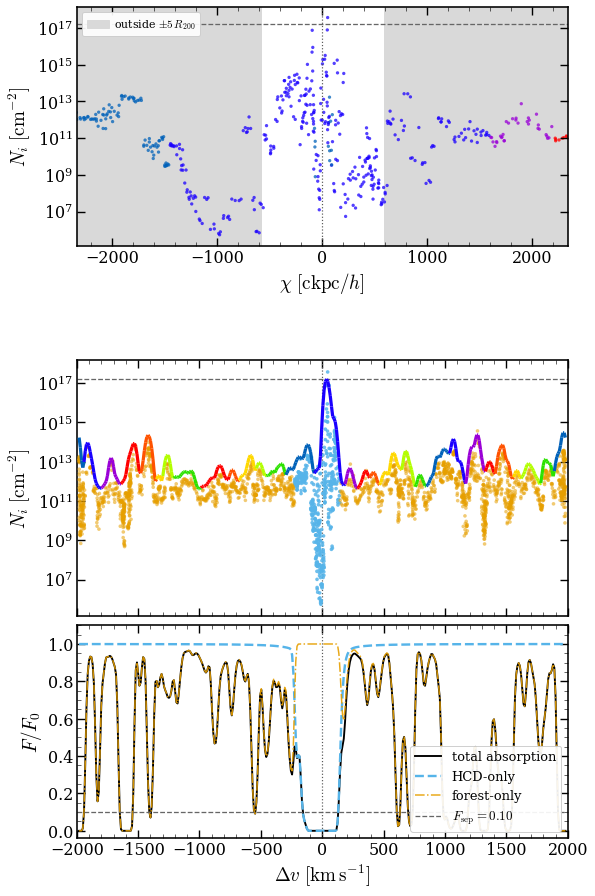


case (d): halo 5, axis 2, Center, r_multiplier = 0.0000  [sub-DLA, production log N_HI 20.01 -> fit 20.01, chi2 = 5.01]
halo 5  log10 M200 = 12.56  R200 = 320.7 ckpc/h
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 1

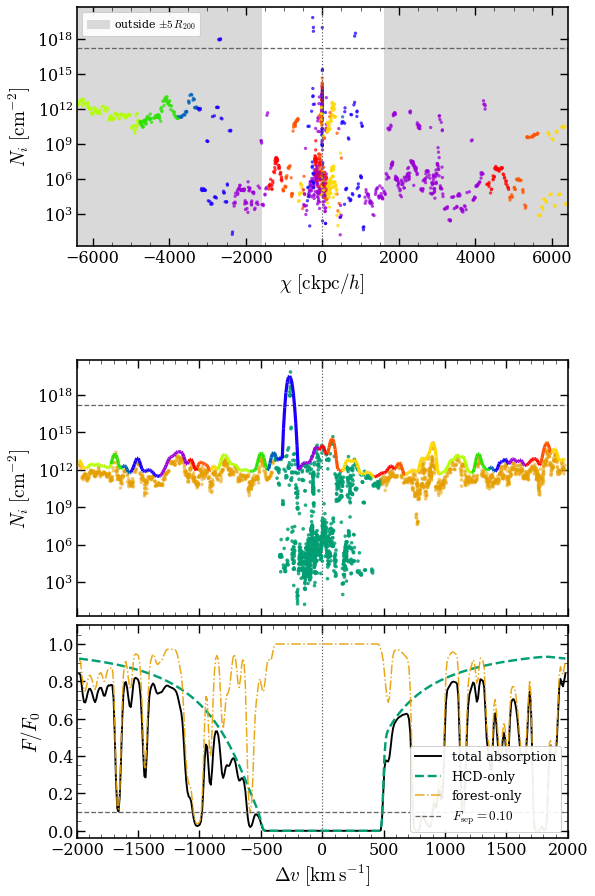


case (e): halo 280, axis 3, Left, r_multiplier = 0.1886  [LLS, production log N_HI 17.28 -> fit 18.86, chi2 = 13.5]
halo 280  log10 M200 = 11.52  R200 = 144.3 ckpc/h
rank = 0 | Interpolation 0.8 percent done
rank = 0 | Interpolation 1.6 percent done
rank = 0 | Interpolation 2.3 percent done
rank = 0 | Interpolation 3.1 percent done
rank = 0 | Interpolation 3.9 percent done
rank = 0 | Interpolation 4.7 percent done
rank = 0 | Interpolation 5.5 percent done
rank = 0 | Interpolation 6.2 percent done
rank = 0 | Interpolation 7.0 percent done
rank = 0 | Interpolation 7.8 percent done
rank = 0 | Interpolation 8.6 percent done
rank = 0 | Interpolation 9.4 percent done
rank = 0 | Interpolation 10.2 percent done
rank = 0 | Interpolation 10.9 percent done
rank = 0 | Interpolation 11.7 percent done
rank = 0 | Interpolation 12.5 percent done
rank = 0 | Interpolation 13.3 percent done
rank = 0 | Interpolation 14.1 percent done
rank = 0 | Interpolation 14.8 percent done
rank = 0 | Interpolation 15.

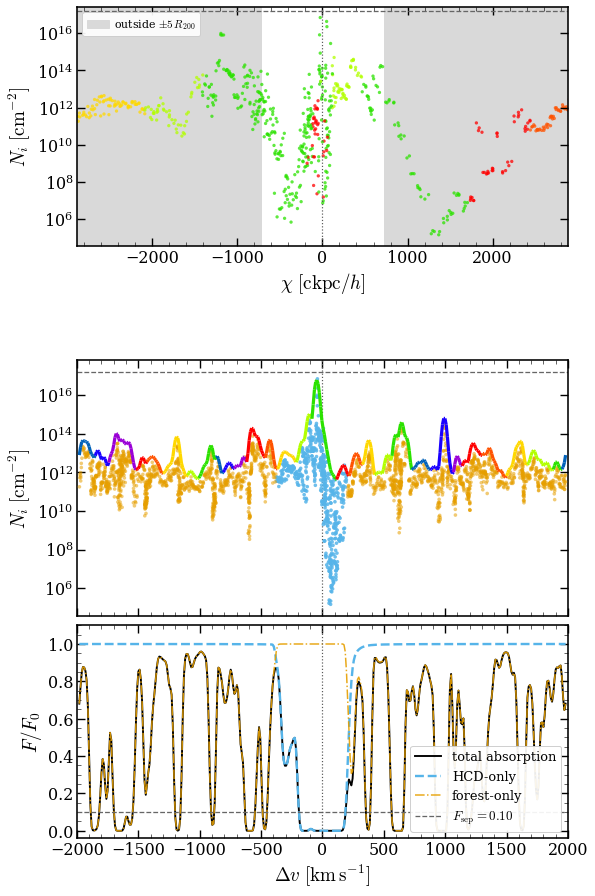

In [9]:
# =============================================================================
# CELL 7 -- run it for (b), (d) and (e)
# =============================================================================
results = {}
for case in CASES:
    results[case['letter']] = make_fig2d_for_case(case)
